# 03 — Data Audit

Checks that the published split was used and looks for duplicate or near-duplicate images across train, val, and test. No model from this study is used.

## 1. Configuration

In [1]:
!pip -q install imagehash

import hashlib, json, shutil, time
from itertools import combinations
from pathlib import Path

import imagehash
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from PIL import Image
from google.colab import drive
drive.mount('/content/drive')

# Paths (adjust to your Google Drive)
DATA_DIR     = Path('/content/drive/MyDrive/USK-Coffee')
LOCAL_DIR    = Path('/content/USK-Coffee')
ORIG_ARCHIVE = Path('/content/drive/MyDrive/USK-Coffee_original.zip')  # archive from the dataset authors
ORIG_DIR     = Path('/content/USK-Coffee-original')
OUT_DIR      = Path('/content/drive/MyDrive/coffee-two-stage/audit')
OUT_DIR.mkdir(parents=True, exist_ok=True)

CLASSES = ['defect', 'longberry', 'peaberry', 'premium']
SPLITS  = ['train', 'val', 'test']
EXPECTED_COUNT = {'train': 1200, 'val': 400, 'test': 400}
EXTS = {'.jpg', '.jpeg', '.png', '.bmp'}

PHASH_MAX_DIST = 10  # Hamming distance (out of 64 bits) for near-duplicate candidates
TOP_K = 50           # most similar pairs shown per split pair

Mounted at /content/drive


## 2. Copy data to the Colab disk

In [2]:
def list_images(folder):
    return sorted(f for f in folder.iterdir() if f.suffix.lower() in EXTS)

t0 = time.time()
for split in SPLITS:
    dst = LOCAL_DIR / split
    ok = dst.exists() and all(
        (dst / c).exists() and len(list_images(dst / c)) == EXPECTED_COUNT[split] for c in CLASSES)
    if not ok:
        shutil.rmtree(dst, ignore_errors=True)
        shutil.copytree(DATA_DIR / split, dst)
    for c in CLASSES:
        assert len(list_images(dst / c)) == EXPECTED_COUNT[split], f'{split}/{c} incomplete'
print(f'done in {time.time() - t0:.0f}s')

done in 125s


## 3. Split manifest

In [3]:
def md5_of(path):
    h = hashlib.md5()
    with open(path, 'rb') as f:
        for block in iter(lambda: f.read(1 << 20), b''):
            h.update(block)
    return h.hexdigest()

def build_inventory(root):
    rows = []
    for split in SPLITS:
        for c in CLASSES:
            for f in list_images(root / split / c):
                with Image.open(f) as img:
                    w, h, mode, fmt = *img.size, img.mode, img.format
                rows.append({'image_id': f'{split}/{c}/{f.name}', 'split': split, 'class': c,
                             'filename': f.name, 'md5': md5_of(f), 'width': w, 'height': h,
                             'mode': mode, 'format': fmt, 'bytes': f.stat().st_size})
    return pd.DataFrame(rows)

inv = build_inventory(LOCAL_DIR)
inv.to_csv(OUT_DIR / 'split_manifest.csv', index=False)

print(inv.pivot_table(index='class', columns='split', values='filename', aggfunc='count')[SPLITS])
print('sizes  :', inv.groupby(['width', 'height']).size().to_dict())
print('modes  :', inv['mode'].value_counts().to_dict())
print('formats:', inv['format'].value_counts().to_dict())

split      train  val  test
class                      
defect      1200  400   400
longberry   1200  400   400
peaberry    1200  400   400
premium     1200  400   400
sizes  : {(256, 256): 8000}
modes  : {'RGB': 8000}
formats: {'JPEG': 8000}


## 4. Comparison with the original release

In [4]:
def find_split_root(root):
    # Folder that directly contains train/val/test
    for d in [root, *sorted(p for p in root.rglob('*') if p.is_dir())]:
        if all((d / s).is_dir() for s in SPLITS):
            return d
    raise FileNotFoundError(f'no train/val/test folders under {root}')

orig_status, cmp = 'not_checked', None
if ORIG_ARCHIVE.exists():
    if not ORIG_DIR.exists():
        shutil.unpack_archive(str(ORIG_ARCHIVE), str(ORIG_DIR))
    orig = build_inventory(find_split_root(ORIG_DIR))

    cmp = inv[['image_id', 'md5']].merge(orig[['image_id', 'md5']], on='image_id', how='outer',
                                         suffixes=('_local', '_orig'), indicator=True)
    orig_md5 = orig.groupby('md5')['image_id'].apply(list).to_dict()
    local_ids, local_md5 = set(inv['image_id']), set(inv['md5'])

    def classify(r):
        if r['_merge'] == 'both':
            return 'match' if r['md5_local'] == r['md5_orig'] else 'content_differs'
        if r['_merge'] == 'left_only':
            src = orig_md5.get(r['md5_local'], [])
            if not src:
                return 'only_in_local'
            # Same content exists elsewhere in the original: moved, or an extra copy
            return 'moved' if any(s not in local_ids for s in src) else 'extra_copy'
        return 'moved_away' if r['md5_orig'] in local_md5 else 'only_in_original'

    cmp['status'] = cmp.apply(classify, axis=1)
    cmp = cmp.drop(columns='_merge')
    cmp.to_csv(OUT_DIR / 'original_comparison.csv', index=False)
    orig_status = 'identical' if (cmp['status'] == 'match').all() else 'differences_found'
    print(cmp['status'].value_counts().to_string())
print('original release check:', orig_status)

status
match    8000
original release check: identical


## 5. Exact duplicates

In [5]:
rows = []
for md5, g in inv.groupby('md5'):
    for (_, a), (_, b) in combinations(g.iterrows(), 2):
        rows.append({'md5': md5, 'image_a': a['image_id'], 'image_b': b['image_id'],
                     'split_pair': '-'.join(sorted({a['split'], b['split']}, key=SPLITS.index)),
                     'same_class': a['class'] == b['class']})
exact = pd.DataFrame(rows, columns=['md5', 'image_a', 'image_b', 'split_pair', 'same_class'])
exact.to_csv(OUT_DIR / 'exact_duplicates.csv', index=False)

cross_exact = exact[exact['split_pair'].str.contains('-')]
print('exact duplicate pairs        :', len(exact))
print('  across splits              :', len(cross_exact), cross_exact['split_pair'].value_counts().to_dict())
print('  with conflicting class     :', int((~exact['same_class']).sum()))

exact duplicate pairs        : 0
  across splits              : 0 {}
  with conflicting class     : 0


## 6. Near-duplicates (perceptual hash)

In [6]:
POPCOUNT = np.array([bin(i).count('1') for i in range(256)], dtype=np.uint8)
idx = {s: inv.index[inv['split'] == s].to_numpy() for s in SPLITS}
path_of = lambda image_id: LOCAL_DIR / image_id

def phash_bytes(img):
    return np.packbits(imagehash.phash(img).hash.flatten())

def get_hashes(ids, variants):
    out = []
    for i in ids:
        with Image.open(path_of(i)) as img:
            img = img.convert('RGB')
            if variants:
                # 4 rotations x with/without flip, to catch rotated or mirrored copies
                imgs = [r for k in range(4) for r in
                        (img.rotate(90 * k, expand=True),
                         img.rotate(90 * k, expand=True).transpose(Image.Transpose.FLIP_LEFT_RIGHT))]
                out.append(np.stack([phash_bytes(v) for v in imgs]))
            else:
                out.append(phash_bytes(img)[None])
    return np.stack(out)  # (n, variants, 8 bytes)

def min_hamming(query, ref, chunk=100):
    ref = ref[:, 0]
    d = np.empty((len(query), len(ref)), dtype=np.uint8)
    for s in range(0, len(query), chunk):
        x = query[s:s + chunk, :, None] ^ ref[None, None]
        d[s:s + chunk] = POPCOUNT[x].sum(-1, dtype=np.uint8).min(1)  # smallest distance over variants
    return d

h_base = {s: get_hashes(inv.loc[idx[s], 'image_id'], variants=False) for s in SPLITS}
h_var  = {s: get_hashes(inv.loc[idx[s], 'image_id'], variants=True) for s in ['val', 'test']}

PAIRS = [('test', 'train'), ('val', 'train'), ('val', 'test')]  # (query, reference)
dist, cands = {}, []
for q, r in PAIRS:
    d = dist[(q, r)] = min_hamming(h_var[q], h_base[r])
    qi, ri = np.nonzero(d <= PHASH_MAX_DIST)
    qd, rd = inv.loc[idx[q]].reset_index(drop=True), inv.loc[idx[r]].reset_index(drop=True)
    cands.append(pd.DataFrame({'split_pair': f'{r}-{q}',
                               'query_image': qd['image_id'].to_numpy()[qi],
                               'ref_image': rd['image_id'].to_numpy()[ri],
                               'hamming': d[qi, ri].astype(int),
                               'same_class': qd['class'].to_numpy()[qi] == rd['class'].to_numpy()[ri]}))
phash_cand = pd.concat(cands, ignore_index=True).sort_values(['hamming', 'split_pair']).reset_index(drop=True)
phash_cand.insert(0, 'pair_no', np.arange(1, len(phash_cand) + 1))
phash_cand.to_csv(OUT_DIR / 'phash_candidates.csv', index=False)

print(pd.DataFrame({f'<= {t}': [int((dist[p] <= t).sum()) for p in PAIRS] for t in [0, 4, 8, PHASH_MAX_DIST]},
                   index=[f'{r}-{q}' for q, r in PAIRS]))

            <= 0  <= 4   <= 8   <= 10
train-test     9  2346  42935  119937
train-val      6  1906  39582  114563
test-val       2   832  14798   41056


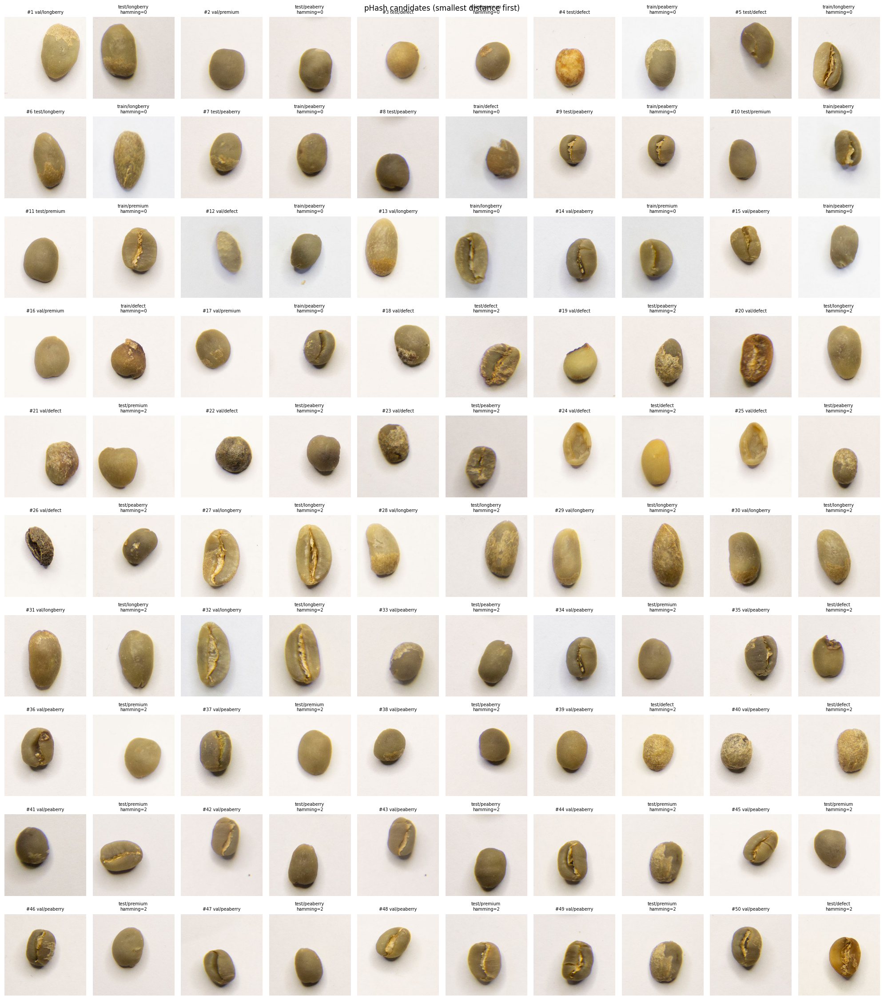

In [7]:
def show_pairs(pairs, score, title, fname, per_row=5):
    pairs = pairs.head(TOP_K)
    if pairs.empty:
        print('no pairs'); return
    n_rows = int(np.ceil(len(pairs) / per_row))
    fig, axes = plt.subplots(n_rows, per_row * 2, figsize=(per_row * 4, n_rows * 2.3), squeeze=False)
    for ax in axes.flat:
        ax.axis('off')
    for i, (_, row) in enumerate(pairs.iterrows()):
        r, c = divmod(i, per_row)
        for j, col in enumerate(['query_image', 'ref_image']):
            with Image.open(path_of(row[col])) as img:
                axes[r, 2 * c + j].imshow(img.convert('RGB'))
            split, cls, _ = row[col].split('/')
            label = f"#{row['pair_no']} {split}/{cls}" if j == 0 else f'{split}/{cls}\n{score}={row[score]:.3g}'
            axes[r, 2 * c + j].set_title(label, fontsize=7)
    fig.suptitle(title)
    plt.tight_layout()
    plt.savefig(OUT_DIR / fname, dpi=110)
    plt.show()

show_pairs(phash_cand, 'hamming', 'pHash candidates (smallest distance first)', 'phash_pairs.png')

## 7. Embedding similarity

In [8]:
import torch
from torch.utils.data import DataLoader
from torchvision import models, transforms

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
eval_tf = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225]),
])

class ImageList(torch.utils.data.Dataset):
    def __init__(self, ids):
        self.ids = list(ids)
    def __len__(self):
        return len(self.ids)
    def __getitem__(self, i):
        with Image.open(path_of(self.ids[i])) as img:
            return eval_tf(img.convert('RGB'))

# ImageNet weights only (not fine-tuned), so the check does not depend on the study's models
backbone = models.resnet50(weights='IMAGENET1K_V1')
backbone.fc = torch.nn.Identity()
backbone = backbone.eval().to(device)

feats = []
with torch.no_grad():
    for x in DataLoader(ImageList(inv['image_id']), batch_size=64, num_workers=2):
        feats.append(backbone(x.to(device)).cpu())
emb = torch.cat(feats).numpy()
emb /= np.linalg.norm(emb, axis=1, keepdims=True)  # cosine similarity = dot product
np.save(OUT_DIR / 'embeddings_resnet50_imagenet.npy', emb)  # row order = split_manifest.csv

nn_rows, top_pairs = [], {}
for q, r in PAIRS:
    sim = emb[idx[q]] @ emb[idx[r]].T
    qd, rd = inv.loc[idx[q]].reset_index(drop=True), inv.loc[idx[r]].reset_index(drop=True)
    best = sim.argmax(1)
    nn_rows.append(pd.DataFrame({'split_pair': f'{r}-{q}', 'query_image': qd['image_id'],
                                 'nearest_image': rd['image_id'].to_numpy()[best],
                                 'cosine': sim[np.arange(len(best)), best],
                                 'same_class': qd['class'].to_numpy() == rd['class'].to_numpy()[best]}))
    flat = np.argsort(sim.ravel())[::-1][:TOP_K]
    qi, ri = np.unravel_index(flat, sim.shape)
    top_pairs[f'{r}-{q}'] = pd.DataFrame({'pair_no': np.arange(1, len(flat) + 1),
                                          'query_image': qd['image_id'].to_numpy()[qi],
                                          'ref_image': rd['image_id'].to_numpy()[ri],
                                          'cosine': sim[qi, ri],
                                          'same_class': qd['class'].to_numpy()[qi] == rd['class'].to_numpy()[ri]})
    top_pairs[f'{r}-{q}'].to_csv(OUT_DIR / f'embedding_top_{r}-{q}.csv', index=False)

nn_table = pd.concat(nn_rows, ignore_index=True)
nn_table.to_csv(OUT_DIR / 'nearest_neighbors.csv', index=False)
print(nn_table.groupby('split_pair')['cosine'].describe()[['min', '50%', 'max']].round(4))

Downloading: "https://download.pytorch.org/models/resnet50-0676ba61.pth" to /root/.cache/torch/hub/checkpoints/resnet50-0676ba61.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 174MB/s]


               min     50%     max
split_pair                        
test-val    0.8239  0.9447  0.9832
train-test  0.8420  0.9545  1.0000
train-val   0.8412  0.9496  0.9822


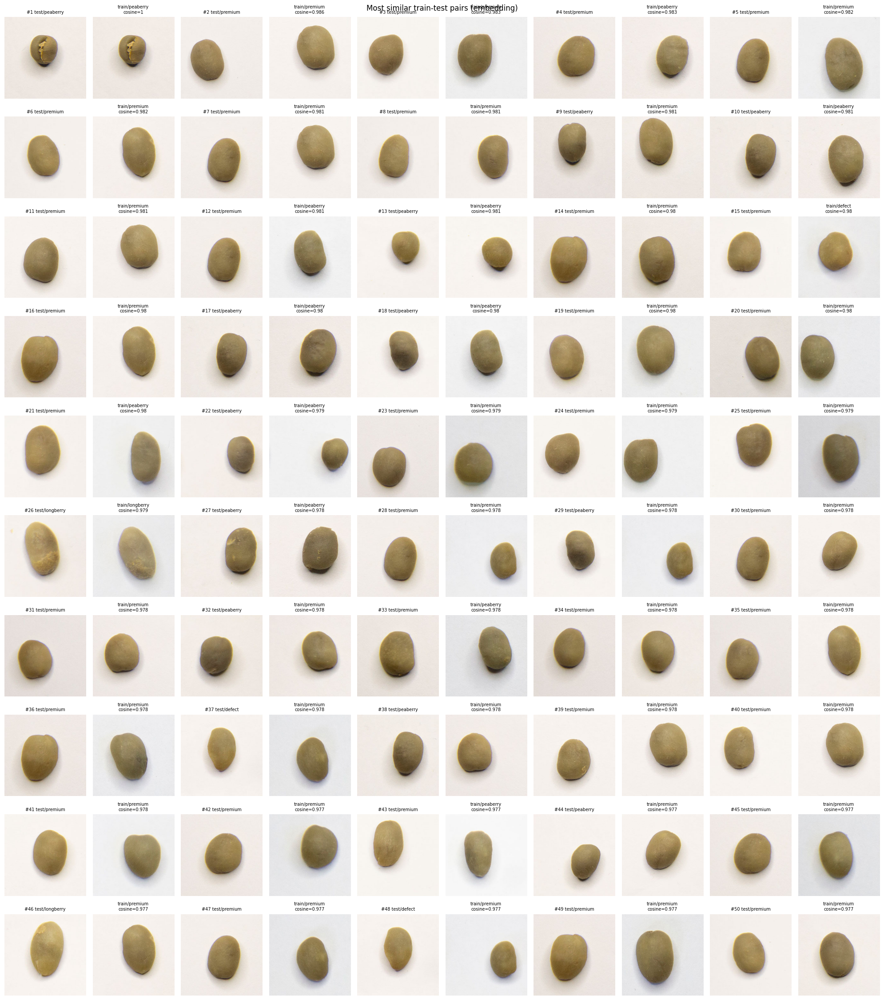

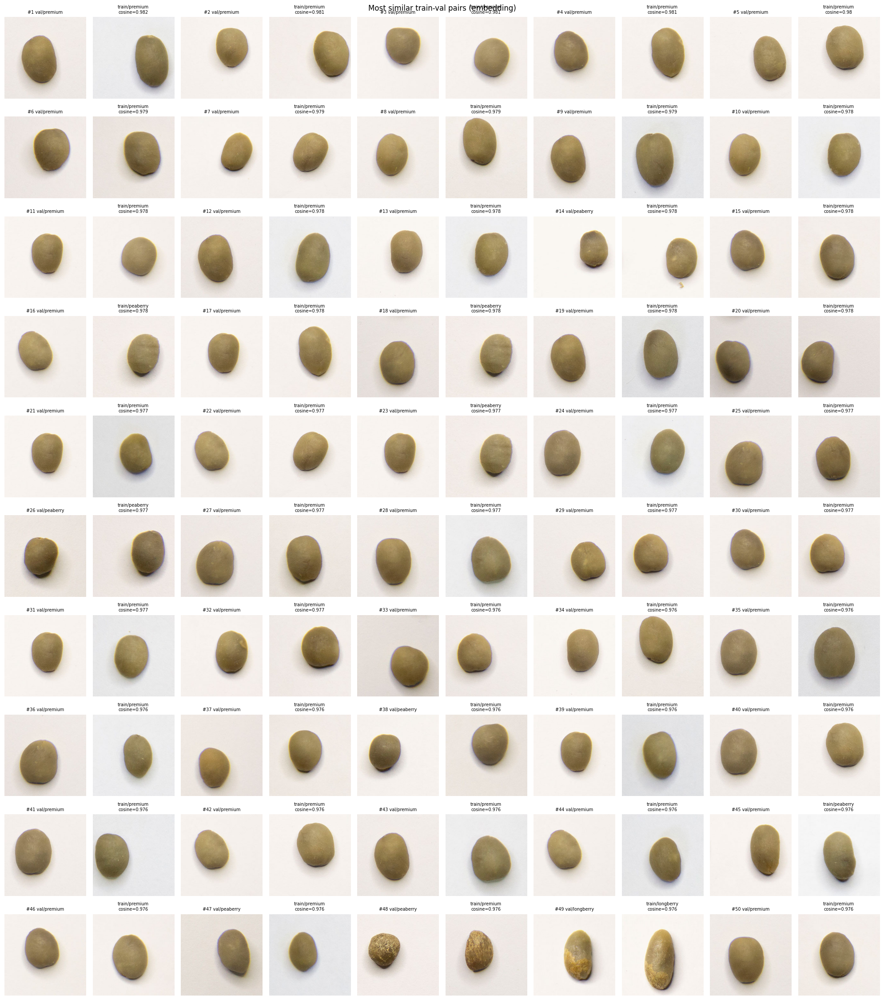

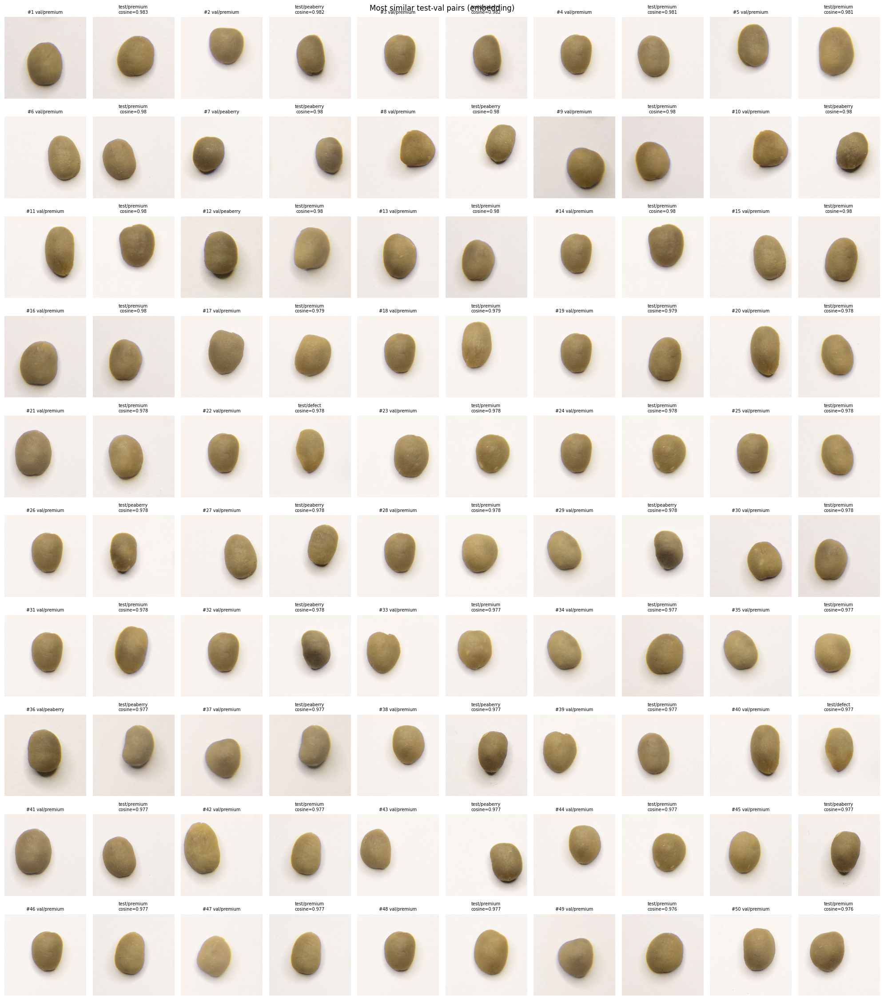

In [9]:
for name, pairs in top_pairs.items():
    show_pairs(pairs, 'cosine', f'Most similar {name} pairs (embedding)', f'embedding_pairs_{name}.png')

## 8. Visual confirmation and summary

In [11]:
# Pair numbers (#n in the figures) that show the same bean. Leave out different beans that only look alike.
# If the last pair shown is still the same bean, raise TOP_K and rerun sections 6-7.
CONFIRMED = {
    'phash': [9],
    'train-test': [1],
    'train-val': [],
    'test-val': [],
}

frames = []
if CONFIRMED['phash']:
    frames.append(phash_cand[phash_cand['pair_no'].isin(CONFIRMED['phash'])])
for name, pairs in top_pairs.items():
    frames.append(pairs[pairs['pair_no'].isin(CONFIRMED[name])].assign(split_pair=name))
conf = pd.concat(frames, ignore_index=True)[['split_pair', 'query_image', 'ref_image', 'same_class']]
if len(conf):
    # The same pair can be found by both methods
    conf = conf[~conf.apply(lambda r: frozenset([r['query_image'], r['ref_image']]), axis=1).duplicated()]
conf.to_csv(OUT_DIR / 'confirmed_duplicates.csv', index=False)

counts = inv.groupby(['split', 'class']).size()
summary = {
    'total_images': len(inv),
    'counts_match_published_split': bool(all(counts[(s, c)] == EXPECTED_COUNT[s] for s in SPLITS for c in CLASSES)),
    'original_release_check': orig_status,
    'original_release_status': cmp['status'].value_counts().to_dict() if cmp is not None else None,
    'exact_duplicates_across_splits': len(cross_exact),
    'exact_duplicates_conflicting_class': int((~exact['same_class']).sum()),
    'phash_candidates': phash_cand['split_pair'].value_counts().to_dict(),
    'embedding_pairs_inspected_per_split_pair': TOP_K,
    'confirmed_duplicates_across_splits': conf['split_pair'].value_counts().to_dict(),
}
with open(OUT_DIR / 'audit_summary.json', 'w') as f:
    json.dump(summary, f, indent=2, default=int)
print(json.dumps(summary, indent=2, default=int))

{
  "total_images": 8000,
  "counts_match_published_split": true,
  "original_release_check": "identical",
  "original_release_status": {
    "match": 8000
  },
  "exact_duplicates_across_splits": 0,
  "exact_duplicates_conflicting_class": 0,
  "phash_candidates": {
    "train-test": 119937,
    "train-val": 114563,
    "test-val": 41056
  },
  "embedding_pairs_inspected_per_split_pair": 50,
  "confirmed_duplicates_across_splits": {
    "train-test": 1
  }
}
